<div style="background-color:#DFC7F2; padding:15px; margin:15px;">


**Центр непрерывного образования НИУ ВШЭ**

## Программа «Python для автоматизации и анализа данных»

### Занятие 7. Часть 1. Работа с файлами



</div>

# Файловый ввод-вывод

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

До этого момента наши программы работали только с данными в **оперативной памяти** — после завершения скрипта всё терялось. Работа с файлами позволяет:
* **сохранять** результаты между запусками программы,
* **читать** большие объёмы данных из внешних источников,
* **обмениваться** данными с другими программами.

В этой части мы разберём чтение и запись **текстовых файлов** (`.txt`, `.csv`, `.py` и им подобные). Двоичные форматы (изображения, архивы) работают по тем же принципам, но с флагом `'b'`.
</div>

## Рабочая директория

Когда вы указываете Python имя файла без полного пути (например, `'data.txt'`), он ищет файл в **рабочей директории** — папке, из которой запущен ваш скрипт или Jupyter-ноутбук.

Модуль <code style="color:red;background:none">os</code> позволяет управлять файловой системой прямо из Python: узнавать текущую директорию, менять её и просматривать содержимое папок.

In [1]:
import os
os.getcwd()  # get current working directory — получить текущую рабочую директорию

'/content'

In [ ]:
'/content/work/data.txt'

### Смена рабочей директории

<code style="color:red;background:none">os.chdir()</code> принимает путь к папке и делает её рабочей. После этого можно обращаться к файлам в ней просто по имени, без полного пути, а все новые файлы будут сохраняться туда же.

> **Важно:** в Windows в строках путей используйте двойной обратный слэш `\\` или сырые строки `r'C:\Users\...'`, так как одинарный `\` является управляющим символом.

In [2]:
# Пример для Windows — замените путь на свой
os.chdir('/')

# os.chdir('C:\\Users\\meale\\HSE\\HSE 2023-2024\\DPO')
os.getcwd()  # убеждаемся, что директория сменилась

'/'

### Просмотр содержимого директории

<code style="color:red;background:none">os.listdir()</code> возвращает **список** всех файлов и папок в текущей директории. Это особенно полезно, если нужно обработать несколько файлов в цикле — не нужно перечислять их имена вручную.

In [3]:
os.listdir()  # покажет все файлы и папки в текущей директории

['lib',
 'sbin',
 'etc',
 'lib64',
 'media',
 'mnt',
 'usr',
 'home',
 'proc',
 'root',
 'tmp',
 'run',
 'sys',
 'dev',
 'boot',
 'var',
 'srv',
 'opt',
 'bin',
 'kaggle',
 '.dockerenv',
 'tools',
 'datalab',
 'content',
 'python-apt',
 'python-apt.tar.xz',
 'sbin.usr-is-merged',
 'bin.usr-is-merged',
 'lib.usr-is-merged']

## Открытие файла: функция <code style="color:red;background:none">open()</code>

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

Функция <code style="color:red;background:none">open()</code> — главный инструмент для работы с файлами. Она возвращает **файловый объект** (file handle, дескриптор файла), через который и происходит вся работа.

Сигнатура: `open(filename, mode='r', encoding=None)`

| Режим | Расшифровка | Описание |
|-------|-------------|----------|
| `'r'` | read | Только чтение. Файл **должен** существовать. Режим по умолчанию. |
| `'w'` | write | Только запись. Создаёт файл или **удаляет содержимое** существующего! |
| `'a'` | append | Дозапись в конец файла. Создаёт файл, если не существовал. |
| `'r+'` | read+write | Чтение и запись, файл должен существовать. |
| `'b'` | binary | Двоичный режим (добавляется к другому: `'rb'`, `'wb'`). |

Параметр `encoding='utf-8'` обязателен при работе с кириллицей и другими нелатинскими символами.
</div>

In [5]:
os.chdir('/content')
os.getcwd()

'/content'

In [16]:
# Создаём (или перезаписываем) файл test.txt в режиме записи
f = open('test.txt', 'w', encoding='utf-8')

### Запись и закрытие

Метод <code style="color:red;background:none">.write()</code> записывает строку в файл. Файл нужно **обязательно закрыть** методом <code style="color:red;background:none">.close()</code> после работы:
* данные «сбрасываются» из буфера оперативной памяти на диск,
* освобождаются системные ресурсы,
* другие программы получают доступ к файлу.

Если забыть вызвать `.close()`, Python в конце концов закроет файл сам (сборщик мусора), но это может произойти не сразу — особенно проблематично для больших файлов.

In [17]:
f.write('Hello, world!')  # записали строку
f.close()                  # закрыли файл — данные сохранены на диск

### Чтение файла

Метод <code style="color:red;background:none">.read()</code> читает **весь файл целиком** и возвращает его содержимое в виде строки.

In [8]:
os.chdir('/')
os.getcwd()

'/'

In [9]:
f = open('test.txt', 'r', encoding='utf-8')
print(f.read())  # прочитали весь файл
f.close()

Hello, world!


### Что будет, если читать закрытый файл?

После вызова `.close()` файловый объект становится недействительным. Любая попытка работать с ним вызовет ошибку <code style="color:red;background:none">ValueError</code>:

In [10]:
# Файл уже закрыт — попытка прочитать вызовет ошибку
f.read()

ValueError: I/O operation on closed file.

## Контекстный менеджер <code style="color:red;background:none">with</code>

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

Открывать файлы рекомендуется через конструкцию <code style="color:red;background:none">with ... as</code> — это **контекстный менеджер**.

Преимущества перед ручным `open()` / `close()`:
* файл закрывается **автоматически** при выходе из блока `with`, даже если возникнет исключение,
* нет риска забыть `.close()`,
* код становится чище и читабельнее.
</div>

In [11]:
with open('test.txt', encoding='utf-8') as f:  # режим не указан → 'r' по умолчанию
    read_data = f.read()                          # читаем содержимое в переменную
# здесь блок with завершился → файл закрыт автоматически

In [13]:
with open('test.txt', 'w', encoding='utf-8') as f:
  f.write('1')


In [15]:
with open('test.txt', encoding='utf-8') as f:  # режим не указан → 'r' по умолчанию
    read_data = f.read()

print(read_data)

1


In [12]:
print(read_data)

Hello, world!


### Дозапись в файл

Режим <code style="color:red;background:none">'a'</code> (append) добавляет текст **в конец** существующего файла, не затрагивая его предыдущее содержимое. Режим `'w'` при этом **удалил бы** старый текст.

In [18]:
with open('test.txt', 'a', encoding='utf-8') as f:
    f.write('\n Сегодня будет классная погода?\n Или пойдет дождь?')

### Запись через <code style="color:red;background:none">print()</code>

Функция <code style="color:red;background:none">print()</code> умеет писать **прямо в файл** — для этого используется именованный параметр `file`. Удобно, когда нужно форматированно выводить данные: `print()` сам добавляет перенос строки в конце.

In [ ]:
print()

In [24]:
with open('test.txt', 'a', encoding='utf-8') as f:
    print("\nЕще строку написали", file=f)  # print сам добавит \n в конце

UnsupportedOperation: not writable

In [23]:
# Проверим, что всё записалось
with open('test.txt', encoding='utf-8') as f:
    print(f.read())


Hello, world!
 Сегодня будет классная погода?
 Или пойдет дождь?
Еще строку написали



## Методы чтения файла

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

Python предлагает несколько способов читать файл в зависимости от задачи:

| Метод | Что возвращает | Когда использовать |
|-------|----------------|--------------------|
| `.read()` | Вся строка целиком | Небольшие файлы, нужно всё сразу |
| `.read(n)` | Первые `n` символов | Частичное чтение, потоковая обработка |
| `.readline()` | Одна строка | Ручное построчное чтение |
| `.readlines()` | Список всех строк | Нужен список строк в памяти |
| `for line in f` | По одной строке | Большие файлы, экономия памяти |
</div>

### <code style="color:red;background:none">.readline()</code> — читать по одной строке

Метод читает текст до ближайшего символа переноса строки `\n` включительно. При каждом следующем вызове **курсор сдвигается** вперёд, и метод читает следующую строку.

In [26]:
f = open('test.txt', 'r', encoding='utf-8')
f.readline()  # первый вызов → первая строка

'Hello, world!\n'

In [27]:
f.readline()  # второй вызов → вторая строка

' Сегодня будет классная погода?\n'

<code style="color:red;background:none">.readline()</code> работает как **генератор**: каждый вызов выдаёт следующую строку. Внутри файлового объекта хранится **позиция курсора** — указатель на текущее место в файле.

In [28]:
f.readline()  # третий вызов → третья строка

' Или пойдет дождь?\n'

In [29]:
f.close()

### Итерация по файлу в цикле

Самый удобный и **экономичный по памяти** способ читать файл — итерировать по нему в цикле `for`. Python читает файл построчно, не загружая всё в память сразу.

> **Важно:** файловый объект — это **одноразовый итератор**. Когда курсор дошёл до конца файла, повторный цикл ничего не выдаст — нужно либо закрыть и снова открыть файл, либо перемотать курсор.

In [30]:
f = open('test.txt', 'r', encoding='utf-8')

for line in f: # -> for line in f.readlines():
    print(line, end='')  # end='' убирает двойной перенос (\n уже есть в строке)

print('\n--- Второй цикл (ничего не выведет!) ---')
for line in f:           # курсор уже в конце файла
    print(line, end='')

f.close()

Hello, world!
 Сегодня будет классная погода?
 Или пойдет дождь?
Еще строку написали

--- Второй цикл (ничего не выведет!) ---


In [34]:
f = open('test.txt', 'r', encoding='utf-8')
# lines  = f.readlines()
for line in  f.readlines():
    print(line, end='')  # end='' убирает двойной перенос (\n уже есть в строке)

print('\n--- Второй цикл (ничего не выведет!) ---')
for line in  f.readlines():           # курсор уже в конце файла
    print(line, end='')

f.close()

Hello, world!
 Сегодня будет классная погода?
 Или пойдет дождь?
Еще строку написали

--- Второй цикл (ничего не выведет!) ---


### <code style="color:red;background:none">.seek()</code> — перемотка курсора

Метод <code style="color:red;background:none">.seek(n)</code> перемещает курсор на позицию `n` байт от начала файла. `.seek(0)` возвращает к самому началу — после этого файл можно читать заново.

In [35]:
f = open('test.txt', 'r', encoding='utf-8')

for line in f:
    print(line, end='')

f.seek(0)  # перематываем курсор в начало
print('\n--- После seek(0) ---')
for line in f:  # теперь читает заново!
    print(line, end='')

f.close()

Hello, world!
 Сегодня будет классная погода?
 Или пойдет дождь?
Еще строку написали

--- После seek(0) ---
Hello, world!
 Сегодня будет классная погода?
 Или пойдет дождь?
Еще строку написали


### Частичное чтение: <code style="color:red;background:none">.read(n)</code>

Если передать в `.read()` целое число, Python прочитает **ровно столько символов**. Полезно при потоковой обработке или когда нужно только начало файла.

In [39]:
with open('test.txt', encoding='utf-8') as f:
    print(f.read(5))  # читаем только первые 6 символов
    # print(f.read(5))  # читаем только первые 6 символов

Hello
, wor


### <code style="color:red;background:none">.readlines()</code> — список строк

Метод загружает **все строки файла в список**. Каждый элемент — одна строка, включая символ `\n` в конце. То же самое даёт `list(f)`.

In [40]:
f = open('test.txt', 'r', encoding='utf-8')
print(list(f))      # файловый объект → список строк
f.close()

['Hello, world!\n', ' Сегодня будет классная погода?\n', ' Или пойдет дождь?\n', 'Еще строку написали\n']


In [41]:
f = open('test.txt', 'r', encoding='utf-8')
print(f.readlines())  # то же самое через метод
f.close()

['Hello, world!\n', ' Сегодня будет классная погода?\n', ' Или пойдет дождь?\n', 'Еще строку написали\n']


## Практический пример: анализ почтового лога

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

Файл `mbox.txt` — это лог электронных писем в формате mbox. Каждое письмо содержит множество строк с метаданными. Нас интересуют строки вида:

```
Date: Sat, 5 Jan 2008 09:12:18 -0500
```

**Задача:** посчитать, в какой час суток (0–23) было отправлено больше всего писем, и сохранить статистику в словарь.
</div>

### Шаг 1: найти нужные строки

Отфильтруем строки, начинающиеся с `'Date: '`:

In [ ]:
open('mbox.txt', encoding='utf-8') as f:

In [ ]:
f = open('/Users/drkocharyan/DPO/lecture_7/mbox.txt', 'r', encoding='utf-8')
''.join(f.readlines()) # первый вызов → первая строка
# 'From stephen.marquard@uct.ac.za Sat Jan 5 09:14:16 2008\n\nReturn-Path: <postmaster@collab.sakaiproject.org>\n\nReceived: from murder (mail.umich.edu [141.211.14.90])\n\nby frankenstein.mail.umich.edu (Cyrus v2.3.8) with LMTPA;\n\nSat, 05 Jan 2008 09:14:16 -0500\n\nX-Sieve: CMU Sieve 2.3\n\nReceived: from murder ([unix socket])\n\nby mail.umich.edu (Cyrus v2.2.12) with LMTPA;\n\nSat, 05 Jan 2008 09:14:16 -0500\n\nReceived: from holes.mr.itd.umich.edu (holes.mr.itd.umich.edu [141.211.14.79])\n\nby flawless.mail.umich.edu () with ESMTP id m05EEFR1013674;\n\nSat, 5 Jan 2008 09:14:15 -0500\n\nReceived: FROM paploo.uhi.ac.uk (app1.prod.collab.uhi.ac.uk [194.35.219.184])\n\nBY holes.mr.itd.umich.edu ID 477F90B0.2DB2F.12494 ;\n\n5 Jan 2008 09:14:10 -0500\n\nReceived: from paploo.uhi.ac.uk (localhost [127.0.0.1])\n\nby paploo.uhi.ac.uk (Postfix) with ESMTP id 5F919BC2F2;\n\nSat, 5 Jan 2008 14:10:05 +0000 (GMT)\n\nMessage-ID: <200801051412.m05ECIaH010327@nakamura.uits.iupui.edu>\n\nMime-Version: 1.0\n\nContent-Transfer-Encoding: 7bit\n\nReceived: from prod.collab.uhi.ac.uk ([194.35.219.182])\n\nby paploo.uhi.ac.uk (JAMES SMTP Server 2.1.3) with SMTP ID 899\n\nfor <source@collab.sakaiproject.org>;\n\nSat, 5 Jan 2008 14:09:50 +0000 (GMT)\n\nReceived: from nakamura.uits.iupui.edu (nakamura.uits.iupui.edu [134.68.220.122])\n\nby shmi.uhi.ac.uk (Postfix) with ESMTP id A215243002\n\nfor <source@collab.sakaiproject.org>; Sat, 5 Jan 2008 14:13:33 +0000 (GMT)\n\nReceived: from nakamura.uits.iupui.edu (localhost [127.0.0.1])\n\nby nakamura.uits.iupui.edu (8.12.11.20060308/8.12.11) with ESMTP id m05ECJVp010329\n\nfor <source@collab.sakaiproject.org>; Sat, 5 Jan 2008 09:12:19 -0500\n\nReceived: (from apache@localhost)\n\nby nakamura.uits.iupui.edu (8.12.11.20060308/8.12.11/Submit) id m05ECIaH010327\n\nfor source@collab.sakaiproject.org; Sat, 5 Jan 2008 09:12:18 -0500\n\nDate: Sat, 5 Jan 2008 09:12:18 -0500\n\nX-Authentication-Warning: nakamura.uits.iupui.edu: apache set sender to stephen.marquard@uct.ac.za using -f\n\nTo: source@collab.sakaiproject.org\n\nFrom: stephen.marquard@uct.ac.za\n\nSubject: [sakai] svn commit: r39772 - content/branches/sakai_2-5-x/content-impl/impl/src/java/org/sakaiproject/content/impl\n\nX-Content-Type-Outer-Envelope: text/plain; charset=UTF-8\n\nX-Content-Type-Message-Body: text/plain; charset=UTF-8\n\nContent-Type: text/plain; charset=UTF-8\n\nX-DSPAM-Result: Innocent\n\nX-DSPAM-Processed: Sat Jan 5 09:14:16 2008\n\nX-DSPAM-Confidence: 0.8475\n\nX-DSPAM-Probability: 0.0000\n\nDetails: http://source.sakaiproject.org/viewsvn/?view=rev&rev=39772\n\nAuthor: stephen.marquard@uct.ac.za\n\nDate: 2008-01-05 09:12:07 -0500 (Sat, 05 Jan 2008)\n\nNew Revision: 39772\n\nModified:\n\ncontent/branches/sakai_2-5-x/content-impl/impl/src/java/org/sakaiproject/content/impl/ContentServiceSqlOracle.java\n\ncontent/branches/sakai_2-5-x/content-impl/impl/src/java/org/sakaiproject/content/impl/DbContentService.java\n\nLog:\n\nSAK-12501 merge to 2-5-x: r39622, r39624:5, r39632:3 (resolve conflict from differing linebreaks for r39622)\n\n----------------------\n\nThis automatic notification message was sent by Sakai Collab (https://collab.sakaiproject.org/portal) from the Source site.\n\nYou can modify how you receive notifications at My Workspace > Preferences.\n\nFrom louis@media.berkeley.edu Fri Jan 4 18:10:48 2008\n\nReturn-Path: <postmaster@collab.sakaiproject.org>\n\nReceived: from murder (mail.umich.edu [141.211.14.97])\n\nby frankenstein.mail.umich.edu (Cyrus v2.3.8) with LMTPA;\n\nFri, 04 Jan 2008 18:10:48 -0500\n\nX-Sieve: CMU Sieve 2.3\n\nReceived: from murder ([unix socket])\n\nby mail.umich.edu (Cyrus v2.2.12) with LMTPA;\n\nFri, 04 Jan 2008 18:10:48 -0500\n\nReceived: from icestorm.mr.itd.umich.edu (icestorm.mr.itd.umich.edu [141.211.93.149])\n\nby sleepers.mail.umich.edu () with ESMTP id m04NAbGa029441;\n\nFri, 4 Jan 2008 18:10:37 -0500\n\nReceived: FROM paploo.uhi.ac.uk (app1.prod.collab.uhi.ac.uk [194.35.219.184])\n\nBY icestorm.mr.itd.umich.edu ID 477EBCE3.161BB.4320 ;\n\n4 Jan 2008 18:10:31 -0500\n\nReceived: from paploo.uhi.ac.uk (localhost [127.0.0.1])\n\nby paploo.uhi.ac.uk (Postfix) with ESMTP id 07969BB706;\n\nFri, 4 Jan 2008 23:10:33 +0000 (GMT)\n\nMessage-ID: <200801042308.m04N8v6O008125@nakamura.uits.iupui.edu>\n\nMime-Version: 1.0\n\nContent-Transfer-Encoding: 7bit\n\nReceived: from prod.collab.uhi.ac.uk ([194.35.219.182])\n\nby paploo.uhi.ac.uk (JAMES SMTP Server 2.1.3) with SMTP ID 710\n\nfor <source@collab.sakaiproject.org>;\n\nFri, 4 Jan 2008 23:10:10 +0000 (GMT)\n\nReceived: from nakamura.uits.iupui.edu (nakamura.uits.iupui.edu [134.68.220.122])'


In [43]:
with open('mbox.txt','w', encoding='utf-8') as f:
  f.write("'From stephen.marquard@uct.ac.za Sat Jan 5 09:14:16 2008\n\nReturn-Path: <postmaster@collab.sakaiproject.org>\n\nReceived: from murder (mail.umich.edu [141.211.14.90])\n\nby frankenstein.mail.umich.edu (Cyrus v2.3.8) with LMTPA;\n\nSat, 05 Jan 2008 09:14:16 -0500\n\nX-Sieve: CMU Sieve 2.3\n\nReceived: from murder ([unix socket])\n\nby mail.umich.edu (Cyrus v2.2.12) with LMTPA;\n\nSat, 05 Jan 2008 09:14:16 -0500\n\nReceived: from holes.mr.itd.umich.edu (holes.mr.itd.umich.edu [141.211.14.79])\n\nby flawless.mail.umich.edu () with ESMTP id m05EEFR1013674;\n\nSat, 5 Jan 2008 09:14:15 -0500\n\nReceived: FROM paploo.uhi.ac.uk (app1.prod.collab.uhi.ac.uk [194.35.219.184])\n\nBY holes.mr.itd.umich.edu ID 477F90B0.2DB2F.12494 ;\n\n5 Jan 2008 09:14:10 -0500\n\nReceived: from paploo.uhi.ac.uk (localhost [127.0.0.1])\n\nby paploo.uhi.ac.uk (Postfix) with ESMTP id 5F919BC2F2;\n\nSat, 5 Jan 2008 14:10:05 +0000 (GMT)\n\nMessage-ID: <200801051412.m05ECIaH010327@nakamura.uits.iupui.edu>\n\nMime-Version: 1.0\n\nContent-Transfer-Encoding: 7bit\n\nReceived: from prod.collab.uhi.ac.uk ([194.35.219.182])\n\nby paploo.uhi.ac.uk (JAMES SMTP Server 2.1.3) with SMTP ID 899\n\nfor <source@collab.sakaiproject.org>;\n\nSat, 5 Jan 2008 14:09:50 +0000 (GMT)\n\nReceived: from nakamura.uits.iupui.edu (nakamura.uits.iupui.edu [134.68.220.122])\n\nby shmi.uhi.ac.uk (Postfix) with ESMTP id A215243002\n\nfor <source@collab.sakaiproject.org>; Sat, 5 Jan 2008 14:13:33 +0000 (GMT)\n\nReceived: from nakamura.uits.iupui.edu (localhost [127.0.0.1])\n\nby nakamura.uits.iupui.edu (8.12.11.20060308/8.12.11) with ESMTP id m05ECJVp010329\n\nfor <source@collab.sakaiproject.org>; Sat, 5 Jan 2008 09:12:19 -0500\n\nReceived: (from apache@localhost)\n\nby nakamura.uits.iupui.edu (8.12.11.20060308/8.12.11/Submit) id m05ECIaH010327\n\nfor source@collab.sakaiproject.org; Sat, 5 Jan 2008 09:12:18 -0500\n\nDate: Sat, 5 Jan 2008 09:12:18 -0500\n\nX-Authentication-Warning: nakamura.uits.iupui.edu: apache set sender to stephen.marquard@uct.ac.za using -f\n\nTo: source@collab.sakaiproject.org\n\nFrom: stephen.marquard@uct.ac.za\n\nSubject: [sakai] svn commit: r39772 - content/branches/sakai_2-5-x/content-impl/impl/src/java/org/sakaiproject/content/impl\n\nX-Content-Type-Outer-Envelope: text/plain; charset=UTF-8\n\nX-Content-Type-Message-Body: text/plain; charset=UTF-8\n\nContent-Type: text/plain; charset=UTF-8\n\nX-DSPAM-Result: Innocent\n\nX-DSPAM-Processed: Sat Jan 5 09:14:16 2008\n\nX-DSPAM-Confidence: 0.8475\n\nX-DSPAM-Probability: 0.0000\n\nDetails: http://source.sakaiproject.org/viewsvn/?view=rev&rev=39772\n\nAuthor: stephen.marquard@uct.ac.za\n\nDate: 2008-01-05 09:12:07 -0500 (Sat, 05 Jan 2008)\n\nNew Revision: 39772\n\nModified:\n\ncontent/branches/sakai_2-5-x/content-impl/impl/src/java/org/sakaiproject/content/impl/ContentServiceSqlOracle.java\n\ncontent/branches/sakai_2-5-x/content-impl/impl/src/java/org/sakaiproject/content/impl/DbContentService.java\n\nLog:\n\nSAK-12501 merge to 2-5-x: r39622, r39624:5, r39632:3 (resolve conflict from differing linebreaks for r39622)\n\n----------------------\n\nThis automatic notification message was sent by Sakai Collab (https://collab.sakaiproject.org/portal) from the Source site.\n\nYou can modify how you receive notifications at My Workspace > Preferences.\n\nFrom louis@media.berkeley.edu Fri Jan 4 18:10:48 2008\n\nReturn-Path: <postmaster@collab.sakaiproject.org>\n\nReceived: from murder (mail.umich.edu [141.211.14.97])\n\nby frankenstein.mail.umich.edu (Cyrus v2.3.8) with LMTPA;\n\nFri, 04 Jan 2008 18:10:48 -0500\n\nX-Sieve: CMU Sieve 2.3\n\nReceived: from murder ([unix socket])\n\nby mail.umich.edu (Cyrus v2.2.12) with LMTPA;\n\nFri, 04 Jan 2008 18:10:48 -0500\n\nReceived: from icestorm.mr.itd.umich.edu (icestorm.mr.itd.umich.edu [141.211.93.149])\n\nby sleepers.mail.umich.edu () with ESMTP id m04NAbGa029441;\n\nFri, 4 Jan 2008 18:10:37 -0500\n\nReceived: FROM paploo.uhi.ac.uk (app1.prod.collab.uhi.ac.uk [194.35.219.184])\n\nBY icestorm.mr.itd.umich.edu ID 477EBCE3.161BB.4320 ;\n\n4 Jan 2008 18:10:31 -0500\n\nReceived: from paploo.uhi.ac.uk (localhost [127.0.0.1])\n\nby paploo.uhi.ac.uk (Postfix) with ESMTP id 07969BB706;\n\nFri, 4 Jan 2008 23:10:33 +0000 (GMT)\n\nMessage-ID: <200801042308.m04N8v6O008125@nakamura.uits.iupui.edu>\n\nMime-Version: 1.0\n\nContent-Transfer-Encoding: 7bit\n\nReceived: from prod.collab.uhi.ac.uk ([194.35.219.182])\n\nby paploo.uhi.ac.uk (JAMES SMTP Server 2.1.3) with SMTP ID 710\n\nfor <source@collab.sakaiproject.org>;\n\nFri, 4 Jan 2008 23:10:10 +0000 (GMT)\n\nReceived: from nakamura.uits.iupui.edu (nakamura.uits.iupui.edu [134.68.220.122])'")



In [44]:
with open('mbox.txt', encoding='utf-8') as f:
    for line in f:
        if line.startswith('Date: '):
            print(line)

Date: Sat, 5 Jan 2008 09:12:18 -0500

Date: 2008-01-05 09:12:07 -0500 (Sat, 05 Jan 2008)



### Шаг 2: уточнить фильтр

Видим, что у каждого письма **две строки** с `'Date: '`. Нужна только одна из них — та, которая заканчивается на `)\n` (содержит часовой пояс). Добавим дополнительное условие и проверим на одном примере:

In [45]:
with open('mbox.txt', encoding='utf-8') as f:
    for line in f:
        if line.startswith('Date: ') and line.endswith(')\n'):
            print(line)
            break  # печатаем только первую совпавшую строку для проверки

Date: 2008-01-05 09:12:07 -0500 (Sat, 05 Jan 2008)



In [50]:
line.split()[2].split(':')[1]
# 09:12:07

'12'

### Шаг 3: извлечь час

Строка выглядит так: `Date: Sat, 5 Jan 2008 09:12:18 -0500`

Разбиваем по пробелам — получаем список. Элемент с индексом `[2]` — это время `'09:12:18'`. Затем разбиваем по `':'` и берём первый элемент — час.

In [62]:
with open('mbox.txt', encoding='utf-8') as f:
    for line in f:
        if line.startswith('Date: ') and line.endswith(')\n'):
            hour = line.split()[2].split(':')[0]  # сначала по ' ', потом по ':'
            print(hour)
            break

09


### Шаг 4: собрать статистику в словарь

Используем `dict.get(key, default)` — удобный способ увеличить счётчик, не проверяя заранее, есть ли ключ в словаре.

In [72]:
hours = {}

with open('mbox.txt', encoding='utf-8') as f:
    for line in f:
        if line.startswith('Date: ') and line.endswith(')\n'):
            hour = line.split()[2].split(':')[0]
            # print(line)
            hours[hour] = hours.get(hour, 0) + 1

for hour in sorted(hours):
    print(f'В {hour} часов было отправлено {hours[hour]} писем')

В 02 часов было отправлено 1 писем
В 03 часов было отправлено 1 писем
В 09 часов было отправлено 3 писем
В 10 часов было отправлено 4 писем
В 11 часов было отправлено 2 писем


In [73]:
hours

{'09': 3, '10': 4, '11': 2, '03': 1, '02': 1}

### Шаг 5: визуализация

Построим столбчатую диаграмму распределения писем по часам суток. Для этого подготовим отсортированные ключи (часы) и соответствующие значения (количество писем).

In [74]:
sorted_values = []
for key in sorted(hours.keys()):
    sorted_values.append(hours[key])

In [77]:
hours

{'09': 3, '10': 4, '11': 2, '03': 1, '02': 1}

In [78]:
print(sorted_values)
print(sorted(hours.keys()))

[1, 1, 3, 4, 2]
['02', '03', '09', '10', '11']


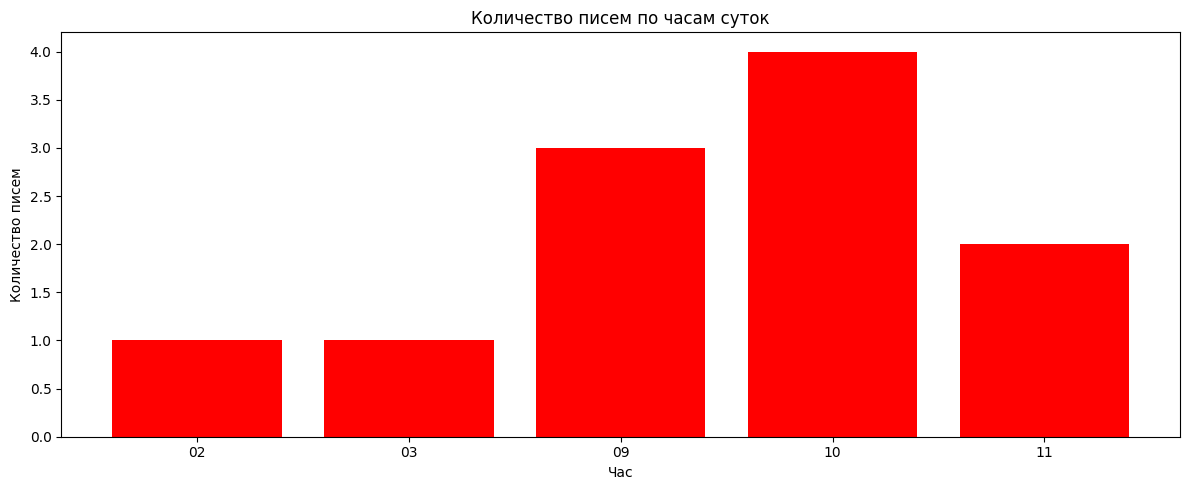

In [82]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(12, 5))
plt.bar(sorted(hours.keys()), sorted_values, color='red')
plt.title('Количество писем по часам суток')
plt.xlabel('Час')
plt.ylabel('Количество писем')
plt.tight_layout()
plt.show()

# Обработка исключений: <code style="color:red;background:none">try / except</code>

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

**Исключение (exception)** — это ошибка, возникающая во время выполнения программы. По умолчанию Python останавливает выполнение и выводит сообщение об ошибке (traceback).

Конструкция <code style="color:red;background:none">try / except</code> позволяет **перехватить** ошибку и вместо краша выполнить альтернативный код. Это особенно важно:
* при работе с файлами (файл может не существовать),
* при чтении данных от пользователя (может ввести не то),
* при сетевых запросах (соединение может оборваться).
</div>

### Пример без обработки ошибки

Попросим пользователя ввести имя файла и попробуем его открыть. Если файл не существует — программа упадёт с <code style="color:red;background:none">FileNotFoundError</code>:

In [83]:
fname = input('Введите название файла: ')
fhand = open(fname)  # если файла нет — здесь будет ошибка и программа остановится

Введите название файла: nothing


FileNotFoundError: [Errno 2] No such file or directory: 'nothing'

### Структура <code style="color:red;background:none">try / except</code>

```python
try:
    # код, который может вызвать ошибку
except:
    # что делать, если ошибка произошла
```

Python выполняет блок `try`. Если в нём возникает **любое** исключение — управление передаётся в `except`. Код после блока `try/except` продолжает работать в любом случае.

In [85]:
fname = input('Введите название файла: ')

try:
    fhand = open(fname)
    count = 0
    for line in fhand:
        if line.startswith('From '):
            count += 1
    fhand.close()
    print('There were', count, 'from lines in', fname)

except:
    print('File cannot be opened:', fname)

print('Программа продолжила работу после ошибки!')

Введите название файла: test.txt
There were 0 from lines in test.txt
Программа продолжила работу после ошибки!


In [86]:
fname = input('Введите название файла: ')

try:
    fhand = open(fname)
    count = 0
    for line in fhand:
        if line.startswith('From '):
            count += 1
    fhand.close()
    print('There were', count, 'from lines in', fname)

except:
    print('File cannot be opened:', fname)

print('Программа продолжила работу после ошибки!')

Введите название файла: noothibg
File cannot be opened: noothibg
Программа продолжила работу после ошибки!


`except` сработал — программа не упала, а вывела понятное сообщение и продолжила работу.

### <code style="color:red;background:none">try / except</code> не только для файлов

Механизм исключений работает с **любым** кодом, а не только с файлами:

In [87]:
try:
    print(y)  # переменная y не определена
except:
    print('Произошла ошибка — но программа не упала!')

Произошла ошибка — но программа не упала!


### Обработка конкретного типа ошибки

Перехватывать **все** исключения подряд — не лучшая практика: можно случайно проглотить важную ошибку. Лучше указывать **конкретный тип** исключения.

Сначала выясним имя нашей ошибки, запустив код без обработки:

In [88]:
print(y)  # NameError: name 'y' is not defined

NameError: name 'y' is not defined

Ошибка называется <code style="color:red;background:none">NameError</code>. Теперь обработаем именно её, а другие — отдельно:

In [89]:
try:
    print(y)
except NameError:
    print('Переменная не определена')
except:
    print('Что-то ещё пошло не так')

Переменная не определена


Проверим: если ошибка другого типа, попадём в нижний `except`:

In [90]:
try:
    print(10 / 0)  # ZeroDivisionError
except NameError:
    print('Переменная не определена')
except:
    print('Что-то ещё пошло не так')  # сработает этот блок

Что-то ещё пошло не так


### <code style="color:red;background:none">raise</code> — пробросить ошибку дальше

Иногда нужно: выполнить какие-то действия при ошибке (например, записать лог), а потом **всё равно** остановить программу с сообщением об ошибке. Для этого в конце `except` ставят <code style="color:red;background:none">raise</code>.

In [93]:
# С raise: сначала выполним код в except, потом всё равно упадём
try:
    print(10 / 0)
except NameError:
    print('Переменная не определена')
except:
    print('Что-то пошло не так — логируем ошибку...')
    raise  # теперь программа упадёт с оригинальным сообщением об ошибке


print('код продолжается')

Что-то пошло не так — логируем ошибку...


ZeroDivisionError: division by zero

In [94]:
def my_div(a,b):
  try:
    print(a / b)
  except NameError:
    print('Переменная не определена')
  except:
    print('Что-то пошло не так, аргументы:', a, b)
    raise  # теперь программа упадёт с оригинальным сообщением об ошибке
my_div(10,1)
my_div(10,0)


10.0
Что-то пошло не так, аргументы: 10 0


ZeroDivisionError: division by zero

In [98]:
try:
    print(10 / 0)
except NameError:
    print('Переменная не определена')
except:
    print('go')

go


In [97]:
# Без raise: ошибка при делении на ноль проглочена, сообщения о ней нет
try:
    print(10 / 0)
except NameError:
    print('Переменная не определена')

# нет общего except → ZeroDivisionError не перехвачен, программа упадёт

ZeroDivisionError: division by zero

### Несколько исключений в одном <code style="color:red;background:none">except</code>

Если несколько типов ошибок нужно обработать **одинаково**, их можно перечислить в одном `except` через запятую в круглых скобках:

In [99]:
try:
    print(10 / 0)
except (NameError, ZeroDivisionError):
    print('Ошибка: переменная не определена или деление на ноль')
except:
    print('Что-то ещё пошло не так')

Ошибка: переменная не определена или деление на ноль


### <code style="color:red;background:none">else</code> в блоке <code style="color:red;background:none">try/except</code>

Блок <code style="color:red;background:none">else</code> выполняется, если в `try` **не возникло** никаких ошибок. Это удобно, чтобы отделить «счастливый путь» от обработки ошибок:

In [105]:
try:
    result = 10 / 1  # всё хорошо, ошибки нет
except ZeroDivisionError:
    print('Деление на ноль!')
else:
    print(f'Успешно: результат = {result}')  # выполнится только если ошибок не было

Успешно: результат = 10.0


### <code style="color:red;background:none">pass</code> — молча проигнорировать ошибку

Если ошибка ожидается и ничего делать не нужно — используйте <code style="color:red;background:none">pass</code>. Программа продолжит работу, не выводя ничего. Часто применяется при парсинге и веб-скрейпинге, когда данные могут прийти в неожиданном формате:

In [106]:
try:
    print(10 / 0)
except NameError:
    print('Переменная не определена')
except:
    pass  # молча проигнорировали ZeroDivisionError — программа продолжила работу

In [109]:
def my_func(a,b):
  pass

my_func(10,1)

## Создание собственных исключений

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

Иногда встроенных ошибок недостаточно: логика вашей программы предполагает **собственные правила** валидации. Можно явно вызвать исключение с помощью <code style="color:red;background:none">raise</code>, передав ему сообщение.
</div>

In [112]:
x = -1

if x < 0:
    raise Exception('Ошибка: отрицательные числа не допускаются')

Exception: Ошибка: отрицательные числа не допускаются

Можно использовать **конкретный тип** встроенного исключения с собственным сообщением — это помогает вызывающему коду понять, что именно пошло не так:

In [113]:
x = 'hello'

if not isinstance(x, int):
    raise TypeError('Ошибка: ожидалось целое число, получено ' + type(x).__name__)

TypeError: Ошибка: ожидалось целое число, получено str

In [117]:
print(type(x) == float)

False


## Практический пример: запрос числа у пользователя

Классическая задача: ждать правильного ввода от пользователя, не падая при некорректных данных. Оборачиваем `int(input())` в бесконечный цикл с `try/except` — выходим из цикла (`break`) только при успешной конвертации:

In [118]:
while True:
    try:
        x = int(input('Введите целое число: '))
        break  # если конвертация прошла — выходим из цикла
    except ValueError:
        print('Это не целое число. Попробуйте ещё раз.')

print(f'Вы ввели число: {x}')

Введите целое число: hghg
Это не целое число. Попробуйте ещё раз.
Введите целое число: бабаба
Это не целое число. Попробуйте ещё раз.
Введите целое число: 10.2
Это не целое число. Попробуйте ещё раз.
Введите целое число: 10
Вы ввели число: 10
